# Figure 1. Classical laws and equations of speed and accuracy

**What it is.** The four classical records, each with its line, and the square-root rule of force.

**How it works.** Reads the transcribed tables and the values read from the published figures, fits one least-squares line to each record and draws the five panels.

**Files read.** `data/read_from_figures/hyman1953_fig1_GC_experiment1.csv`, `data/read_from_figures/schmidt1979_fig8_fig9_distance_We.csv`, `data/transcribed/fitts1954_table1.csv`, `data/transcribed/woodworth1899_tables_I-IV_right_hand.csv`, `figures/style.py`.

**To run.** Open this notebook from the `notebooks` folder of the repository, or from its root, and run all cells.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
import logging, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
logging.getLogger("matplotlib").setLevel(logging.ERROR)
plt.ioff()
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "figures"), str(ROOT / "code")]

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle, Circle, Polygon, FancyArrowPatch
from matplotlib.lines import Line2D

from style import Sheet, inset, INK, EDGE, RULE, GREY, demand_colour, tb_axes

T = ROOT / "data" / "transcribed"
RF = ROOT / "data" / "read_from_figures"
S = Sheet(6.5, 3.62)
W_, H_ = 1.18, 1.16
Y1, Y2 = 2.22, 0.40
axA, axB, axC = (S.ax(x, Y1, W_, H_) for x in (0.62, 2.62, 4.62))
axD, axE = (S.ax(x, Y2, W_, H_) for x in (1.62, 3.62))
EQ = dict(fontsize=6.6)
OPEN = "#6E8C99"
MK = dict(mec=EDGE, mew=0.45, zorder=3)

def scatter(ax, x, y, c, marker="o", s=2.9):
    for xi, yi, ci in zip(x, y, c):
        ax.plot(xi, yi, marker, ms=s, mfc=ci, **MK)

## A. Woodworth (1899), transcribed Tables I to IV

In [3]:
w = pd.read_csv(T / "woodworth1899_tables_I-IV_right_hand.csv")
m = w.groupby(["condition", "rate_per_min"]).average_error_mm.mean().unstack(0)
ax = axA
ax.plot(m.index, m["eyes_shut"], color=OPEN, lw=0.9, ls=(0, (3.0, 1.6)), marker="o", ms=2.6, mfc="white", mec=OPEN,
        mew=0.7, zorder=2)
ax.plot(m.index, m["eyes_open"], color=INK, lw=1.0, zorder=2)
scatter(ax, m.index, m["eyes_open"], demand_colour(m.index, 20, 200))
ax.text(24, m["eyes_shut"].iloc[0] + 0.45, "eyes shut", fontsize=6.4, color=OPEN)
ax.text(64, 0.42, "eyes open", fontsize=6.4)
ax.set_xlabel("rate, movements per minute", labelpad=1)
ax.set_ylabel("average error, mm", labelpad=1.5)
tb_axes(ax, xticks=[20, 110, 200], xlim=(10, 210), yticks=[0, 3, 6], ylim=(0, 7.2))
a = inset(ax, [0.58, 0.04, 0.42, 0.34])
a.add_patch(Polygon([[0.7, 0.8], [2.3, 0.8], [1.5, 4.6]], closed=True, fc="white", ec=EDGE, lw=0.6))
a.plot([1.5, 2.1], [1.4, 4.2], color=EDGE, lw=0.6)
for y_, x1 in ((4.0, 9.1), (2.4, 8.8), (0.8, 9.3)):
    a.plot([3.4, x1], [y_, y_], color=EDGE, lw=0.8)
a.text(6.3, 4.75, "equal lines", ha="center", fontsize=5.6)

## B. Hick's law in Hyman (1953), Figure 1, participant G. C., Experiment I, read from the figure

In [4]:
h = pd.read_csv(RF / "hyman1953_fig1_GC_experiment1.csv")
ax = axB
x = np.linspace(0, 3.1, 20)
bh, ah = np.polyfit(h.information_bits, h.rt_ms, 1)
ax.plot(x, ah + bh * x, color=INK, lw=0.9, zorder=2)
scatter(ax, h.information_bits, h.rt_ms, demand_colour(h.information_bits, 0, 3))
ax.text(0.0, 735, rf"$RT = {ah:.0f} + {bh:.0f}\,\log_2 n$ ms", **EQ)
tb_axes(ax, xticks=[0, 1.5, 3], xlim=(-0.15, 3.2), yticks=[200, 450, 700], ylim=(150, 790))
ax.set_xlabel(r"$\log_2 n$, bits", labelpad=1)
ax.set_ylabel("reaction time, ms", labelpad=1.5)
a = inset(ax, [0.56, 0.04, 0.42, 0.36])
for i, x_ in enumerate([1.6, 3.9, 6.2, 8.5]):
    a.add_patch(Circle((x_, 4.3), 0.75, fc=INK if i == 2 else "white", ec=EDGE, lw=0.6))
a.annotate("", xy=(6.2, 2.5), xytext=(6.2, 3.5), arrowprops=dict(arrowstyle="->", color=EDGE, lw=0.5))
a.text(5.0, 1.0, "name the light", ha="center", fontsize=5.6)

## C. Fitts (1954), transcribed Table 1

In [5]:
f = pd.read_csv(T / "fitts1954_table1.csv")
b, a0 = np.polyfit(f.Id_bits, 1000 * f.t_1oz_s, 1)
ax = axC
ax.plot(f.Id_bits, 1000 * f.t_1lb_s, "s", ms=2.6, mfc="white", mec=OPEN, mew=0.7, zorder=2)
x = np.linspace(0.6, 7.4, 20)
ax.plot(x, a0 + b * x, color=INK, lw=0.9, zorder=2)
scatter(ax, f.Id_bits, 1000 * f.t_1oz_s, demand_colour(f.Id_bits, 1, 7))
ax.text(0.7, 815, rf"$MT = {a0:.1f} + {b:.1f}\,ID$ ms", **EQ)
ax.legend(handles=[Line2D([], [], ls="", marker="s", ms=2.6, mfc="white", mec=OPEN, mew=0.7, label="1-lb stylus"),
                   Line2D([], [], ls="", marker="o", ms=2.9, mfc=demand_colour(4, 1, 7), mec=EDGE, mew=0.45,
                          label="1-oz stylus")],
          loc="upper left", bbox_to_anchor=(0.0, 0.90), fontsize=6.2, handletextpad=0.2, borderaxespad=0.1,
          labelspacing=0.15, handlelength=1.0)
ax.set_xlabel(r"$ID = \log_2(2D/W)$, bits", labelpad=1)
ax.set_ylabel("movement time, ms", labelpad=1.5)
tb_axes(ax, xticks=[1, 4, 7], xlim=(0.5, 7.5), yticks=[0, 400, 800], ylim=(0, 880))
a = inset(ax, [0.53, 0.03, 0.46, 0.32])
for x0 in (1.0, 7.4):
    a.add_patch(Rectangle((x0, 1.4), 1.4, 2.6, fc="white", ec=EDGE, lw=0.6, hatch="////"))
a.annotate("", xy=(8.1, 0.75), xytext=(1.7, 0.75), arrowprops=dict(arrowstyle="<->", color=EDGE, lw=0.5))
a.text(4.9, 1.0, "$D$", ha="center", fontsize=6.2)
a.plot([7.4, 8.8], [4.45, 4.45], color=EDGE, lw=0.6)
a.text(8.1, 4.6, "$W$", ha="center", va="bottom", fontsize=6.2)
a.add_patch(FancyArrowPatch((2.4, 3.4), (7.4, 3.4), connectionstyle="arc3,rad=-0.35", arrowstyle="<->",
                            mutation_scale=5, color=EDGE, lw=0.6))

## D. Schmidt et al. (1979), Figure 9, distance errors, read from the figure

In [6]:
sz = pd.read_csv(RF / "schmidt1979_fig8_fig9_distance_We.csv")
ax = axD
v = np.linspace(0, 225, 20)
ax.plot(v, 2.12 + 0.033 * v, color=INK, lw=0.9, zorder=2)
SHAPE = {200: "o", 170: "s", 140: "^"}
for mt, mk in SHAPE.items():
    g = sz[sz.MT_ms == mt]
    scatter(ax, g.A_over_MT_fig9_cm_s, g.We_mm_fig9, demand_colour(g.A_over_MT_fig9_cm_s, 50, 210), marker=mk,
            s=3.0 if mk != "^" else 3.3)
ax.legend(handles=[Line2D([], [], ls="", marker=SHAPE[mt], ms=2.8, mfc="white", mec=EDGE, mew=0.6, label=f"{mt}")
                   for mt in SHAPE], title="$MT$, ms", loc="upper left", bbox_to_anchor=(0.0, 0.90), fontsize=6.2,
          title_fontsize=6.2, handletextpad=0.2, borderaxespad=0.1, labelspacing=0.15, handlelength=1.0)
ax.text(5, 10.25, r"$W_e = 2.12 + 0.033\,D/MT$", **EQ)
tb_axes(ax, xticks=[0, 100, 200], xlim=(0, 230), yticks=[0, 5, 10], ylim=(0, 11.0))
ax.set_xlabel(r"average velocity $D/MT$, cm/s", labelpad=1)
ax.set_ylabel(r"spread $W_e$, mm", labelpad=1.5)
a = inset(ax, [0.56, 0.04, 0.42, 0.30])
a.add_patch(Circle((1.4, 2.4), 0.45, fc=INK, ec=INK))
a.annotate("", xy=(6.4, 2.4), xytext=(2.0, 2.4), arrowprops=dict(arrowstyle="->", color=EDGE, lw=0.6))
xs = np.linspace(6.6, 9.8, 60)
a.plot(xs, 1.2 + 2.4 * np.exp(-0.5 * ((xs - 8.2) / 0.5) ** 2), color=EDGE, lw=0.6)
a.plot([6.6, 9.8], [1.2, 1.2], color=EDGE, lw=0.5)
a.plot([8.2, 8.2], [1.0, 3.9], color=RULE, lw=0.5, ls=":")
a.text(4.2, 3.0, "$D$", ha="center", fontsize=6.2)

## E. Newell et al. (1984), Equation 4: the square-root rule and the proportional rise; no data

In [7]:
ax = axE
u = np.linspace(0, 16, 200)
ax.plot(u, u, color=OPEN, lw=0.9, ls=(0, (3.0, 1.6)), zorder=2)
ax.plot(u, np.sqrt(u), color=INK, lw=0.9, zorder=3)
ax.text(1.0, 15.2, r"$\sigma_u = \sigma_1\sqrt{u}$", **EQ)
ax.text(9.6, 11.4, "proportional,\nSchmidt et al.", fontsize=6.0, color=OPEN, ha="right", va="bottom", linespacing=1.05)
ax.text(15.8, 0.9, "square root,\nEquation 4", fontsize=6.0, ha="right", va="bottom", linespacing=1.05)
tb_axes(ax, xticks=[0, 8, 16], xlim=(0, 16.5), yticks=[0, 8, 16], ylim=(0, 17.0))
ax.set_xlabel(r"force, in units $u$", labelpad=1)
ax.set_ylabel(r"spread, $\sigma_u/\sigma_1$", labelpad=1.5)
a = inset(ax, [0.62, 0.31, 0.36, 0.27])
for j in range(4):
    a.add_patch(Rectangle((2.4, 0.4 + 1.0 * j), 1.6, 0.85, fc="white", ec=EDGE, lw=0.5))
a.text(1.9, 2.4, "$u$", ha="right", va="center", fontsize=6.2)
xs = np.linspace(5.4, 9.6, 60)
a.plot(xs, 0.6 + 3.6 * np.exp(-0.5 * ((xs - 7.5) / 0.7) ** 2), color=EDGE, lw=0.6)
a.plot([5.4, 9.6], [0.6, 0.6], color=EDGE, lw=0.5)

for ax, letter, title in ((axA, "A", "Woodworth (1899)"), (axB, "B", "Hick (1952), Hyman (1953)"), (axC, "C", "Fitts (1954)")):
    S.head_over(ax, letter, title)
for ax, letter, title in ((axD, "D", "Schmidt et al. (1979)"), (axE, "E", "Newell et al. (1984)")):
    bb = ax.get_position()
    S.head(letter, title, (bb.x0 + bb.x1) / 2 * S.fw, y=Y2 + H_ + 0.10)

print(f'(Fitts 1-oz fit: MT = {a0:.1f} + {b:.1f} ID ms)')

(Fitts 1-oz fit: MT = 12.8 + 94.7 ID ms)


## The figure

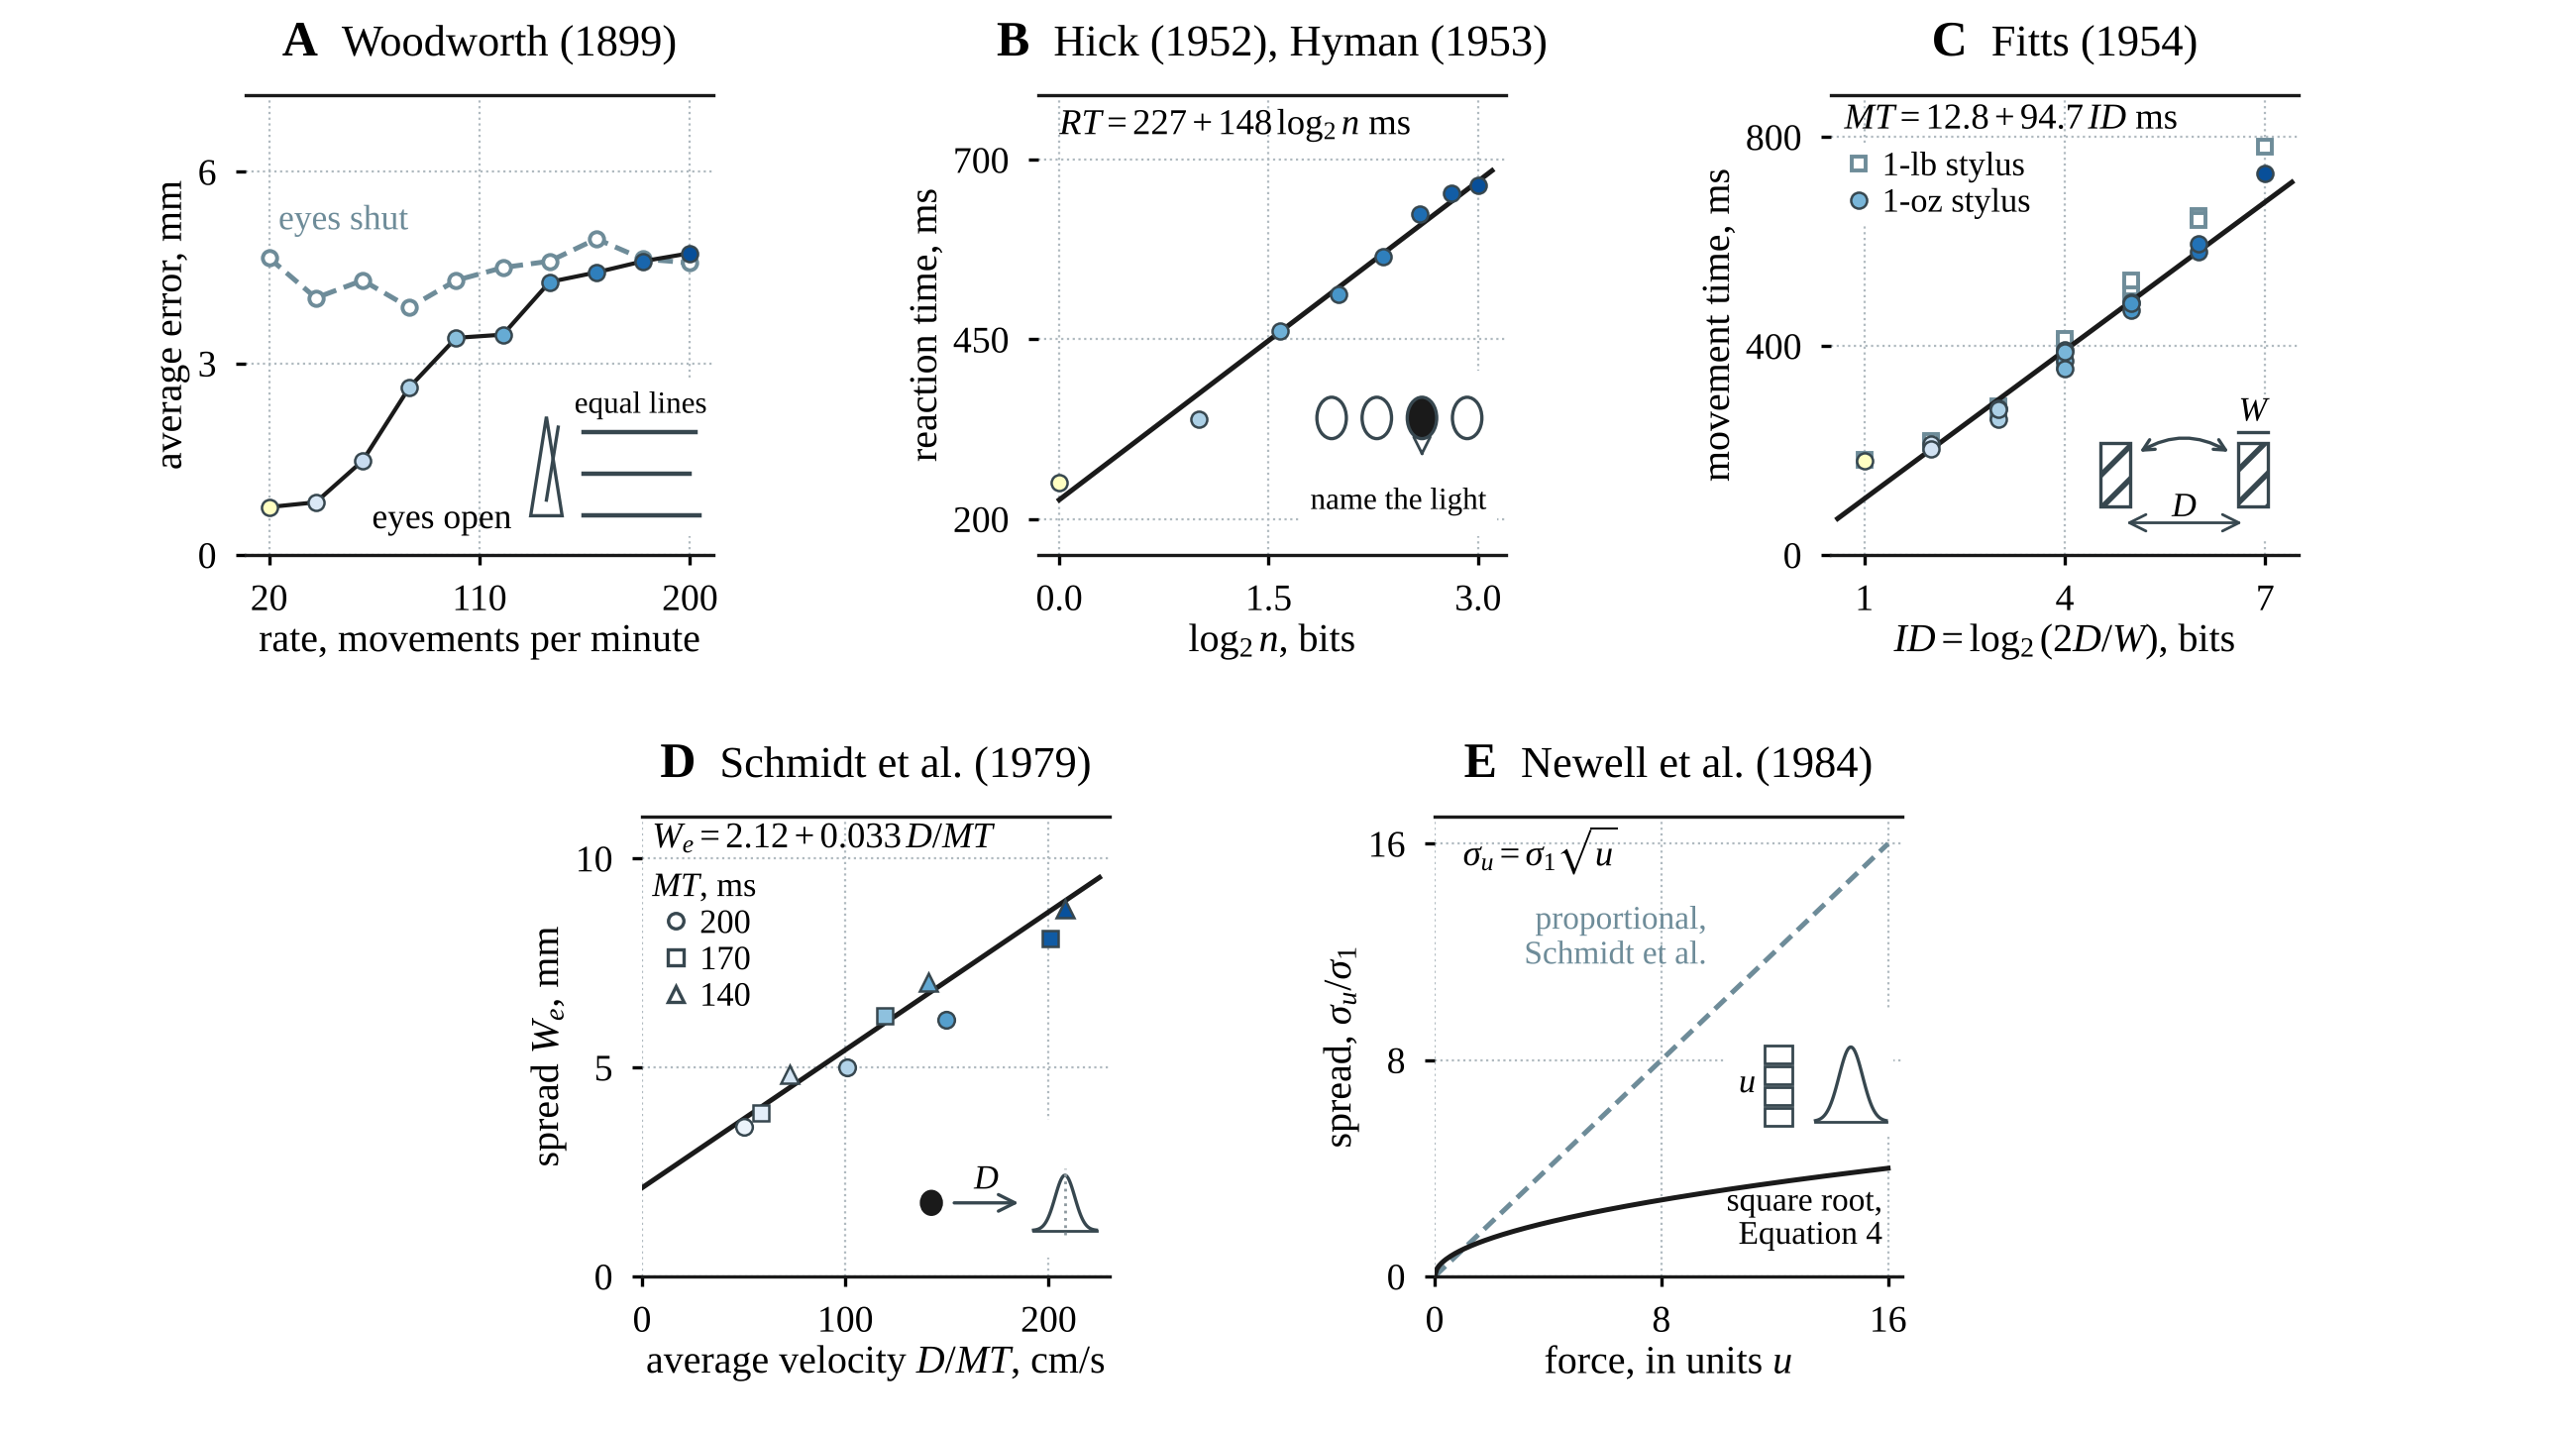

In [8]:
from style import bolden
bolden(S.fig)
display(S.fig)
plt.close("all")

## In the paper

Printed here, then as the manuscript or the Supplemental Material gives it.

- `MT = 12.8 + 94.7 ID`: the line of Fitts' Table 1 in the main text and in Figure 8A.